Training: seed 42, mean 120.03
Test    : seed 2026, mean 120.06
Stochastic Q: 120 | Deterministic Q: 120
Stochastic minus Deterministic: ₹0.0 (95% interval ± ₹0.0)


,Q,avg_profit,se_profit,p5_profit,median_profit,p95_profit,avg_unsold,avg_unmet,stockout_freq
policy,,,,,,,,,
Deterministic,120.0,76151.06,94.94,55200.0,80800.0,83800.0,4.35,4.42,0.47
Stochastic,120.0,76151.06,94.94,55200.0,80800.0,83800.0,4.35,4.42,0.47


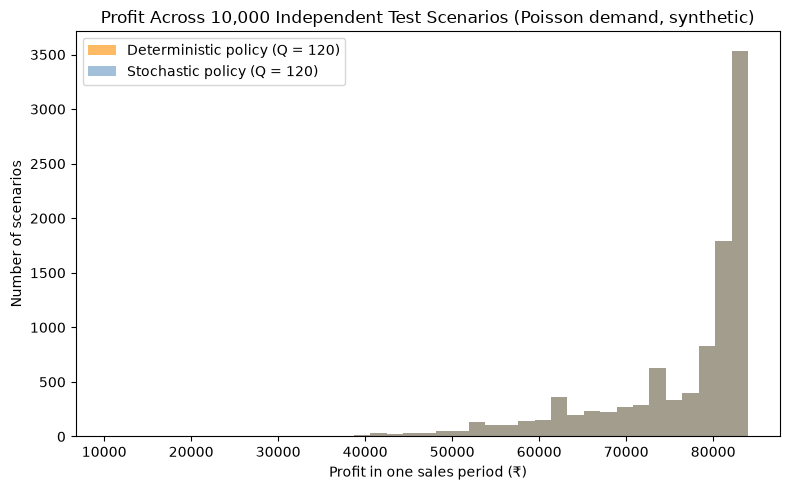

,demand,Q_deterministic,Q_stochastic,avg_profit_det,avg_profit_stoch,diff_stoch_minus_det,diff_ci95_half_width,stockout_freq_det,stockout_freq_stoch,p5_profit_det,p5_profit_stoch
0,Poisson (variance 120),120,120,76151.1,76151.1,0.0,0.0,0.475,0.475,55200.0,55200.0
1,NegBin (variance 240),120,120,72737.7,72737.7,0.0,0.0,0.467,0.467,44000.0,44000.0
2,NegBin (variance 480),120,119,68137.1,68163.9,26.8,17.6,0.469,0.485,29600.0,30500.0


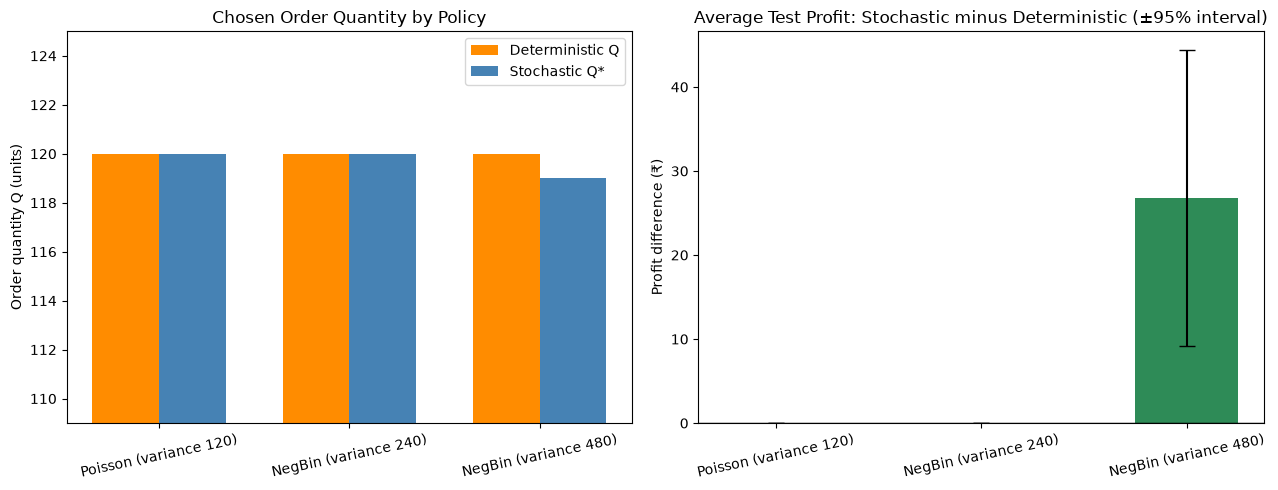

Saved both tables.


In [4]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append(os.path.abspath(".."))
from src.parameters import (COSTS, Q_MAX, MEAN_DEMAND, N_SCENARIOS,
                            SEED_TRAIN, SEED_TEST, NB_VARIANCES)
from src.demand import generate_demand
from src.optimization import find_optimal_q
from src.deterministic import find_deterministic_q
from src.evaluation import evaluate_policy, paired_difference

GRAPHS_DIR = os.path.join("..", "results", "graphs")
TABLES_DIR = os.path.join("..", "results", "tables")
os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

# Training (chooses Q) and independent test data (only for comparison)
train = pd.read_csv(os.path.join("..", "data", "processed",
                                 "synthetic_demand_clean.csv"))["poisson"].to_numpy()
test = generate_demand("poisson", MEAN_DEMAND, N_SCENARIOS, SEED_TEST)
assert SEED_TRAIN != SEED_TEST
assert not np.array_equal(train, test), "Test data must differ from training data"
print(f"Training: seed {SEED_TRAIN}, mean {train.mean():.2f}")
print(f"Test    : seed {SEED_TEST}, mean {test.mean():.2f}")

# The two policies
Q_stoch = find_optimal_q(train, Q_MAX, **COSTS)["best_q"]
Q_det = find_deterministic_q(MEAN_DEMAND, Q_MAX, **COSTS)["best_q"]
print("Stochastic Q:", Q_stoch, "| Deterministic Q:", Q_det)

# Same test scenarios for both
res = {"Deterministic": evaluate_policy(Q_det, test, **COSTS),
       "Stochastic": evaluate_policy(Q_stoch, test, **COSTS)}
cols = ["Q", "avg_profit", "se_profit", "p5_profit", "median_profit", "p95_profit",
        "avg_unsold", "avg_unmet", "stockout_freq"]
base_table = pd.DataFrame({n: {c: r[c] for c in cols} for n, r in res.items()}).T.round(2)
base_table.index.name = "policy"
d_mean, d_se = paired_difference(res["Stochastic"]["profits"], res["Deterministic"]["profits"])
print(f"Stochastic minus Deterministic: ₹{d_mean:,.1f} (95% interval ± ₹{1.96 * d_se:,.1f})")
display(base_table)

# Profit distribution plot
plt.figure(figsize=(8, 5))
bins = np.linspace(min(r["profits"].min() for r in res.values()),
                   max(r["profits"].max() for r in res.values()), 40)
plt.hist(res["Deterministic"]["profits"], bins=bins, alpha=0.6, color="darkorange",
         label=f"Deterministic policy (Q = {Q_det})")
plt.hist(res["Stochastic"]["profits"], bins=bins, alpha=0.5, color="steelblue",
         label=f"Stochastic policy (Q = {Q_stoch})")
plt.title("Profit Across 10,000 Independent Test Scenarios (Poisson demand, synthetic)")
plt.xlabel("Profit in one sales period (₹)")
plt.ylabel("Number of scenarios")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "05_policy_profit_distribution.png"), dpi=200)
plt.show()

# Same comparison under more variable demand (mean stays 120)
cases = [("Poisson (variance 120)", "poisson", None)] + \
        [(f"NegBin (variance {v})", "negbin", v) for v in NB_VARIANCES.values()]
rows = []
for label, dist, var in cases:
    tr = generate_demand(dist, MEAN_DEMAND, N_SCENARIOS, SEED_TRAIN, variance=var)
    te = generate_demand(dist, MEAN_DEMAND, N_SCENARIOS, SEED_TEST, variance=var)
    q_s = find_optimal_q(tr, Q_MAX, **COSTS)["best_q"]
    r_s = evaluate_policy(q_s, te, **COSTS)
    r_d = evaluate_policy(Q_det, te, **COSTS)
    dm, dse = paired_difference(r_s["profits"], r_d["profits"])
    rows.append({
        "demand": label, "Q_deterministic": Q_det, "Q_stochastic": q_s,
        "avg_profit_det": round(r_d["avg_profit"], 1),
        "avg_profit_stoch": round(r_s["avg_profit"], 1),
        "diff_stoch_minus_det": round(dm, 1),
        "diff_ci95_half_width": round(1.96 * dse, 1),
        "stockout_freq_det": round(r_d["stockout_freq"], 3),
        "stockout_freq_stoch": round(r_s["stockout_freq"], 3),
        "p5_profit_det": round(r_d["p5_profit"], 0),
        "p5_profit_stoch": round(r_s["p5_profit"], 0),
    })
var_table = pd.DataFrame(rows)
display(var_table)

# Comparison plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(var_table))
w = 0.35
axes[0].bar(x - w/2, var_table["Q_deterministic"], w, color="darkorange", label="Deterministic Q")
axes[0].bar(x + w/2, var_table["Q_stochastic"], w, color="steelblue", label="Stochastic Q*")
axes[0].set_xticks(x)
axes[0].set_xticklabels(var_table["demand"], rotation=12)
axes[0].set_ylim(var_table[["Q_deterministic", "Q_stochastic"]].min().min() - 10,
                 var_table[["Q_deterministic", "Q_stochastic"]].max().max() + 5)
axes[0].set_title("Chosen Order Quantity by Policy")
axes[0].set_ylabel("Order quantity Q (units)")
axes[0].legend()
axes[1].bar(x, var_table["diff_stoch_minus_det"], 0.5,
            yerr=var_table["diff_ci95_half_width"], capsize=6, color="seagreen")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xticks(x)
axes[1].set_xticklabels(var_table["demand"], rotation=12)
axes[1].set_title("Average Test Profit: Stochastic minus Deterministic (±95% interval)")
axes[1].set_ylabel("Profit difference (₹)")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "06_policy_comparison_by_variability.png"), dpi=200)
plt.show()

# Save tables
base_table.to_csv(os.path.join(TABLES_DIR, "policy_comparison_base.csv"))
var_table.to_csv(os.path.join(TABLES_DIR, "policy_comparison_variability.csv"), index=False)
print("Saved both tables.")

In [5]:
base_table.to_csv(os.path.join(TABLES_DIR, "policy_comparison_base.csv"))
var_table.to_csv(os.path.join(TABLES_DIR, "policy_comparison_variability.csv"), index=False)
print("Saved both tables.")

Saved both tables.


## Module 10 summary
- Training scenarios (seed 42) were used to choose Q. Independent test scenarios (seed 2026, 10,000 Poisson(120) draws) were used only to compare policies.
- Base case: the deterministic and stochastic policies both choose Q = 120, so their results are identical (profit difference ₹0.0).
- On the test scenarios, average profit at Q = 120 is ₹76,151.1, stockout frequency 0.475, and 5th percentile profit ₹55,200. The deterministic model predicted ₹84,000, so it overstates profit.
- NegBin (variance 240): both policies choose Q = 120, so results are identical.
- NegBin (variance 480): stochastic Q* = 119 vs deterministic Q = 120. Average profit difference is ₹26.8 ± 17.6 (95% interval), about 0.04% of profit, so the advantage is statistically detectable but practically negligible.
- With mean demand fixed at 120, higher variability lowers average profit (₹76,151 → ₹72,738 → ₹68,137 at Q = 120) and the 5th percentile profit (₹55,200 → ₹44,000 → ₹29,600).
- Conclusion: in this symmetric-cost setting, stochastic and deterministic optimization recommend almost the same order quantity. The deterministic model's weakness is that it misjudges expected profit and risk.
- All parameter values are illustrative assumptions and demand is synthetic.

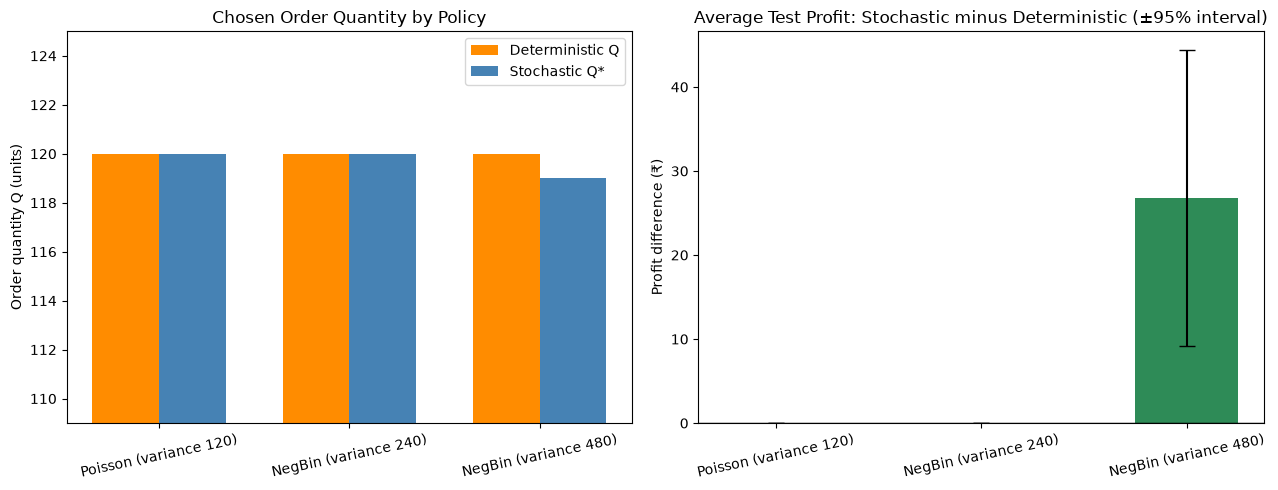

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(var_table))
w = 0.35

axes[0].bar(x - w/2, var_table["Q_deterministic"], w, color="darkorange", label="Deterministic Q")
axes[0].bar(x + w/2, var_table["Q_stochastic"], w, color="steelblue", label="Stochastic Q*")
axes[0].set_xticks(x)
axes[0].set_xticklabels(var_table["demand"], rotation=12)
axes[0].set_ylim(var_table[["Q_deterministic", "Q_stochastic"]].min().min() - 10,
                 var_table[["Q_deterministic", "Q_stochastic"]].max().max() + 5)
axes[0].set_title("Chosen Order Quantity by Policy")
axes[0].set_ylabel("Order quantity Q (units)")
axes[0].legend()

axes[1].bar(x, var_table["diff_stoch_minus_det"], 0.5,
            yerr=var_table["diff_ci95_half_width"], capsize=6, color="seagreen")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xticks(x)
axes[1].set_xticklabels(var_table["demand"], rotation=12)
axes[1].set_title("Average Test Profit: Stochastic minus Deterministic (±95% interval)")
axes[1].set_ylabel("Profit difference (₹)")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "06_policy_comparison_by_variability.png"), dpi=200)
plt.show()

In [7]:
cases = [("Poisson (variance 120)", "poisson", None)] + \
        [(f"NegBin (variance {v})", "negbin", v) for v in NB_VARIANCES.values()]

rows = []
for label, dist, var in cases:
    tr = generate_demand(dist, MEAN_DEMAND, N_SCENARIOS, SEED_TRAIN, variance=var)
    te = generate_demand(dist, MEAN_DEMAND, N_SCENARIOS, SEED_TEST, variance=var)
    q_s = find_optimal_q(tr, Q_MAX, **COSTS)["best_q"]
    r_s = evaluate_policy(q_s, te, **COSTS)
    r_d = evaluate_policy(Q_det, te, **COSTS)
    dm, dse = paired_difference(r_s["profits"], r_d["profits"])
    rows.append({
        "demand": label,
        "Q_deterministic": Q_det, "Q_stochastic": q_s,
        "avg_profit_det": round(r_d["avg_profit"], 1),
        "avg_profit_stoch": round(r_s["avg_profit"], 1),
        "diff_stoch_minus_det": round(dm, 1),
        "diff_ci95_half_width": round(1.96 * dse, 1),
        "stockout_freq_det": round(r_d["stockout_freq"], 3),
        "stockout_freq_stoch": round(r_s["stockout_freq"], 3),
        "p5_profit_det": round(r_d["p5_profit"], 0),
        "p5_profit_stoch": round(r_s["p5_profit"], 0),
    })

var_table = pd.DataFrame(rows)
var_table

,demand,Q_deterministic,Q_stochastic,avg_profit_det,avg_profit_stoch,diff_stoch_minus_det,diff_ci95_half_width,stockout_freq_det,stockout_freq_stoch,p5_profit_det,p5_profit_stoch
0,Poisson (variance 120),120,120,76151.1,76151.1,0.0,0.0,0.475,0.475,55200.0,55200.0
1,NegBin (variance 240),120,120,72737.7,72737.7,0.0,0.0,0.467,0.467,44000.0,44000.0
2,NegBin (variance 480),120,119,68137.1,68163.9,26.8,17.6,0.469,0.485,29600.0,30500.0


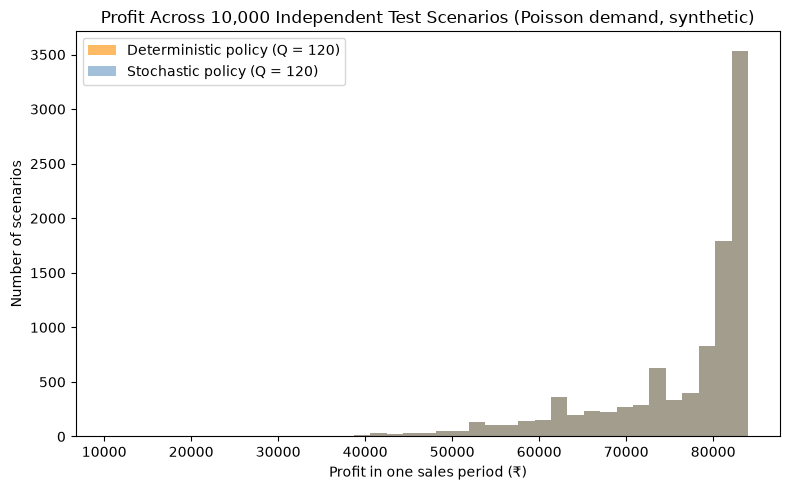

In [8]:
plt.figure(figsize=(8, 5))
bins = np.linspace(min(r["profits"].min() for r in res.values()),
                   max(r["profits"].max() for r in res.values()), 40)
plt.hist(res["Deterministic"]["profits"], bins=bins, alpha=0.6, color="darkorange",
         label=f"Deterministic policy (Q = {Q_det})")
plt.hist(res["Stochastic"]["profits"], bins=bins, alpha=0.5, color="steelblue",
         label=f"Stochastic policy (Q = {Q_stoch})")
plt.title("Profit Across 10,000 Independent Test Scenarios (Poisson demand, synthetic)")
plt.xlabel("Profit in one sales period (₹)")
plt.ylabel("Number of scenarios")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "05_policy_profit_distribution.png"), dpi=200)
plt.show()

In [9]:
res = {
    "Deterministic": evaluate_policy(Q_det, test, **COSTS),
    "Stochastic": evaluate_policy(Q_stoch, test, **COSTS),
}

cols = ["Q", "avg_profit", "se_profit", "p5_profit", "median_profit", "p95_profit",
        "avg_unsold", "avg_unmet", "stockout_freq"]
base_table = pd.DataFrame({name: {c: r[c] for c in cols} for name, r in res.items()}).T.round(2)
base_table.index.name = "policy"

d_mean, d_se = paired_difference(res["Stochastic"]["profits"], res["Deterministic"]["profits"])
print(f"Stochastic minus Deterministic, mean profit difference: ₹{d_mean:,.1f}"
      f"  (95% interval ± ₹{1.96 * d_se:,.1f})")
base_table

Stochastic minus Deterministic, mean profit difference: ₹0.0  (95% interval ± ₹0.0)


,Q,avg_profit,se_profit,p5_profit,median_profit,p95_profit,avg_unsold,avg_unmet,stockout_freq
policy,,,,,,,,,
Deterministic,120.0,76151.06,94.94,55200.0,80800.0,83800.0,4.35,4.42,0.47
Stochastic,120.0,76151.06,94.94,55200.0,80800.0,83800.0,4.35,4.42,0.47


In [10]:
Q_stoch = find_optimal_q(train, Q_MAX, **COSTS)["best_q"]
Q_det = find_deterministic_q(MEAN_DEMAND, Q_MAX, **COSTS)["best_q"]
print("Stochastic-optimal Q (chosen on training data):", Q_stoch)
print("Deterministic-optimal Q (demand fixed at 120) :", Q_det)

Stochastic-optimal Q (chosen on training data): 120
Deterministic-optimal Q (demand fixed at 120) : 120


In [11]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))
from src.parameters import COSTS, Q_MAX, MEAN_DEMAND, N_SCENARIOS, SEED_TRAIN, SEED_TEST, NB_VARIANCES
from src.demand import generate_demand
from src.optimization import find_optimal_q
from src.deterministic import find_deterministic_q
from src.evaluation import evaluate_policy, paired_difference

GRAPHS_DIR = os.path.join("..", "results", "graphs")
TABLES_DIR = os.path.join("..", "results", "tables")

# Training data (used to choose Q) and independent test data (used only to compare)
train = pd.read_csv(os.path.join("..", "data", "processed", "synthetic_demand_clean.csv"))["poisson"].to_numpy()
test = generate_demand("poisson", MEAN_DEMAND, N_SCENARIOS, SEED_TEST)

assert SEED_TRAIN != SEED_TEST
assert not np.array_equal(train, test), "Test data must differ from training data"
print(f"Training: seed {SEED_TRAIN}, mean {train.mean():.2f}")
print(f"Test    : seed {SEED_TEST}, mean {test.mean():.2f}")
print("Test scenarios are independent of training scenarios.")

Training: seed 42, mean 120.03
Test    : seed 2026, mean 120.06
Test scenarios are independent of training scenarios.
